# CampaignScore — Propensity Modeling

> **Case de Machine Learning | Etapa 04 — Modelagem de propensão e priorização de campanhas**

## Contexto do case

O **CampaignScore** é um case de Machine Learning integrante do projeto **CRM Intelligence**, inspirado em um desafio de processo seletivo para Analista de Dados de CRM, proposto por uma empresa brasileira do segmento de delivery de alimentos.

O cenário do desafio representa uma empresa fictícia do varejo alimentício que busca melhorar a rentabilidade de suas campanhas de marketing direto. Uma campanha piloto, realizada com 2.240 clientes, apresentou taxa de conversão de aproximadamente 15%, gerando receita inferior ao custo da ação e um resultado financeiro negativo de 3.046 unidades monetárias (MU).

Esse resultado motivou a busca por uma abordagem orientada por dados, capaz de identificar clientes com maior propensão a aceitar ofertas e direcionar os esforços de marketing de maneira mais eficiente. **O objetivo central do case é desenvolver soluções analíticas que contribuam para maximizar a rentabilidade das campanhas.**

Os dados utilizados são públicos e representam o cenário fictício proposto no desafio, não correspondendo a registros reais de clientes da empresa que o inspirou.

## Objetivo desta etapa

Construir e comparar modelos de classificação capazes de estimar a probabilidade de resposta dos clientes às campanhas de marketing.

A partir dessas estimativas, selecionar um modelo de propensão orientado à rentabilidade, capaz de apoiar a priorização de clientes e a alocação mais eficiente dos recursos destinados às campanhas.

## Escopo e decisões da análise

- A análise utiliza o `PREDICTIVE_DATA`, produzido no Notebook 02 — Feature Selection, composto por 21 features selecionadas para modelagem preditiva, além de `ID` para identificação e `Response` como variável-alvo.
- A base é dividida de forma estratificada em conjuntos de treinamento (80%) e teste (20%), utilizando `RANDOM_STATE = 42`. O conjunto de teste permanece reservado à avaliação final.
- São comparados cinco algoritmos: Regressão Logística, KNN, Árvore de Decisão, XGBoost e LightGBM. A otimização de hiperparâmetros é aplicada aos três candidatos definidos para a etapa: Regressão Logística, XGBoost e LightGBM.
- O pré-processamento é encapsulado nos pipelines, garantindo que imputação, codificação e escalonamento sejam ajustados dentro dos folds de validação.
- A Regressão Logística otimiza também a quantidade de atributos transformados por meio de `SelectKBest`. XGBoost e LightGBM utilizam todas as features transformadas.
- A seleção do modelo é orientada prioritariamente pelo lucro observado médio por 1.000 clientes nas validações cruzadas do conjunto de treinamento. Lucro esperado, Average Precision, ROC-AUC e Brier Score são utilizados como métricas complementares.
- Os parâmetros econômicos são obtidos do `BUSINESS_PARAMETERS`. O custo por contato e a receita por conversão definem o limiar econômico utilizado na simulação de priorização.
- O modelo selecionado é avaliado no conjunto de teste por métricas preditivas, de priorização e econômicas, além de análises de importância por permutação e calibração.
- Após a avaliação, o pipeline campeão é ajustado novamente sobre toda a base disponível e exportado com seus metadados.

A seleção do modelo é fundamentada nas premissas econômicas e nos resultados experimentais do case. As simulações não representam estimativas causais de incrementalidade nem garantem rentabilidade futura.

## Arquivos de saída

- **Pipeline preditivo em Joblib:** caminho definido por `PREDICTIVE_FOLDER`, contendo o pré-processamento e o classificador selecionado, ajustados novamente sobre toda a base disponível.
- **Metadados do modelo em JSON:** arquivo associado ao pipeline, contendo as features utilizadas, hiperparâmetros selecionados, critério de seleção, métricas preditivas e econômicas e premissas de referência.

Os caminhos efetivos dos artefatos são centralizados no módulo `src.paths`.

## 1. Configuração e carregamento dos dados

O notebook consome o dataset apontado pela variável `PREDICTIVE_DATA`, produzido no Notebook 02 — Feature Selection do CampaignScore.

In [1]:
# Importação das bibliotecas e dos caminhos utilizados no notebook
import sys
sys.path.insert(0, "..")

import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    make_scorer,
)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


from src.paths import (
    PREDICTIVE_DATA,
    BUSINESS_PARAMETERS,
    PREDICTIVE_FOLDER,
    
)


In [2]:
# Definição dos parâmetros gerais e dos esquemas de validação cruzada.
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_ITER_SEARCH = 20

cv_comparison = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)
cv_search = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE + 1,
)

In [3]:
# Configuração da exibição das tabelas e do padrão visual dos gráficos
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# Estilo mais limpo: sem molduras superiores/laterais e com grade discreta.
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.35,
})




### 1.1 Funções auxiliares

Esta subseção reúne as funções utilizadas na construção dos pipelines, na avaliação da priorização e na simulação econômica. Elas permanecem neste notebook porque apoiam diretamente o fluxo de modelagem e avaliação aqui desenvolvido.

- **`build_preprocessor()`:** constrói o pré-processamento numérico e categórico, incluindo imputação, padronização opcional e One-Hot Encoding.
- **`build_model_pipeline()`:** combina o pré-processamento, a seleção opcional de atributos por `SelectKBest` e o classificador escolhido.
- **`precision_recall_at_k()`:** calcula precisão e recall entre os clientes com maiores scores, considerando uma fração definida da amostra.
- **`observed_profit_per_1000_scorer()`:** calcula o lucro observado por 1.000 clientes em cada fold, aplicando o limiar econômico do case.
- **`expected_profit_per_1000_scorer()`:** calcula o lucro esperado por 1.000 clientes a partir das probabilidades estimadas dos clientes selecionados.
- **`simulate_campaign_economics()`:** calcula clientes selecionados, conversões, taxas, receitas, custos e lucros esperado e observado para uma política de contato.

In [4]:
# Função auxiliar para construir o pré-processamento numérico e categórico
def build_preprocessor(numeric_cols, categorical_cols, scale_numeric=False):
    """Cria o pré-processamento numérico e categórico.

    Parâmetros
    ----------
    numeric_cols : list[str]
        Colunas numéricas que serão imputadas e, opcionalmente, padronizadas.
    categorical_cols : list[str]
        Colunas categóricas que serão imputadas e codificadas.
    scale_numeric : bool, padrão False
        Define se as variáveis numéricas recebem StandardScaler.

    Retorno
    -------
    ColumnTransformer
        Transformador configurado para produzir uma saída em formato pandas."""

    transformers = []

    # Features numéricas
    if numeric_cols:
        numeric_steps = [
            ("imputer", SimpleImputer(strategy="median"))
        ]

        if scale_numeric:
            numeric_steps.append(("scaler", StandardScaler()))

        transformers.append((
            "numeric",
            Pipeline(numeric_steps),
            numeric_cols
        ))

    # Features categóricas com níveis conhecidos na base curada
    known_cat_cols = [
        col for col in categorical_cols
        if col in KNOWN_CATEGORIES
    ]

    if known_cat_cols:
        known_categories = [
            KNOWN_CATEGORIES[col]
            for col in known_cat_cols
        ]

        known_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                categories=known_categories,
                handle_unknown="ignore",
                sparse_output=False,
            )),
        ])

        transformers.append((
            "categorical_known",
            known_pipeline,
            known_cat_cols
        ))

    # Outras variáveis categóricas, caso existam
    other_cat_cols = [
        col for col in categorical_cols
        if col not in known_cat_cols
    ]

    if other_cat_cols:
        other_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            )),
        ])

        transformers.append((
            "categorical_other",
            other_pipeline,
            other_cat_cols
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=True,
        sparse_threshold=0.0,
    )

    return preprocessor.set_output(transform="pandas")

In [5]:
# Função auxiliar para combinar pré-processamento, seleção opcional e classificador
def build_model_pipeline(estimator, scale_numeric=False, use_feature_selection=False, k="all"):
    """Monta o pipeline completo de pré-processamento e estimação.

    Parâmetros
    ----------
    estimator : estimador compatível com scikit-learn
        Classificador que será incorporado ao pipeline.
    scale_numeric : bool, padrão False
        Define se as features numéricas serão padronizadas.
    use_feature_selection : bool, padrão False
        Indica se SelectKBest será incluído antes do classificador.
    k : int ou str, padrão "all"
        Quantidade de atributos selecionados por SelectKBest.

    Retorno
    -------
    Pipeline
        Pipeline com pré-processamento, seleção opcional e classificador."""
    steps = [(
        "preprocessing",
        build_preprocessor(numeric_features, categorical_features, scale_numeric=scale_numeric),
    )]
    if use_feature_selection:
        steps.append(("feature_selection", SelectKBest(score_func=f_classif, k=k)))
    steps.append(("model", clone(estimator)))
    return Pipeline(steps)

In [6]:
# Função auxiliar para avaliar a priorização por fração dos maiores scores
def precision_recall_at_k(y_true, scores, share):
    """Calcula Precision@K e Recall@K para a fração de maiores scores.

    Parâmetros
    ----------
    y_true : array-like
        Rótulos reais da amostra.
    scores : array-like
        Probabilidades ou scores de resposta estimados pelo modelo.
    share : float
        Fração de clientes priorizada, entre 0 e 1.

    Retorno
    -------
    tuple
        Precisão, recall e quantidade de clientes selecionados."""
    y_array = np.asarray(y_true)
    score_array = np.asarray(scores)
    n_selected = max(1, int(np.ceil(len(score_array) * share)))
    selected_idx = np.argsort(score_array)[::-1][:n_selected]
    positives_selected = int(y_array[selected_idx].sum())
    total_positives = int(y_array.sum())
    precision_k = positives_selected / n_selected
    recall_k = positives_selected / total_positives if total_positives else np.nan
    return precision_k, recall_k, n_selected

In [7]:
# Função auxiliar para calcular o lucro observado por 1.000 clientes
def observed_profit_per_1000_scorer(estimator, X_valid, y_valid):
    """Calcula o lucro observado por 1.000 clientes em um fold de validação.

    A seleção utiliza o limiar econômico definido pelas premissas do case.

    Parâmetros
    ----------
    estimator : estimador compatível com scikit-learn
        Pipeline ajustado no fold de treinamento.
    X_valid : DataFrame
        Preditores do fold de validação.
    y_valid : array-like
        Respostas reais do fold de validação.

    Retorno
    -------
    float
        Lucro observado normalizado para 1.000 clientes."""
    probabilities = estimator.predict_proba(X_valid)[:, 1]
    y_array = np.asarray(y_valid, dtype=int)

    selected = probabilities >= ECONOMIC_THRESHOLD

    selected_customers = int(selected.sum())
    observed_conversions = int(y_array[selected].sum())

    observed_profit = (
        observed_conversions * REVENUE_PER_CONVERSION
        - selected_customers * CONTACT_COST
    )

    return float(observed_profit / len(y_array) * 1000)

In [8]:
# Função auxiliar para calcular o lucro esperado por 1.000 clientes
def expected_profit_per_1000_scorer(estimator, X_valid, y_valid):
    """Calcula o lucro esperado por 1.000 clientes em um fold de validação.

    A expectativa de conversões é obtida pela soma das probabilidades
    estimadas para os clientes selecionados pelo limiar econômico.

    Parâmetros
    ----------
    estimator : estimador compatível com scikit-learn
        Pipeline ajustado no fold de treinamento.
    X_valid : DataFrame
        Preditores do fold de validação.
    y_valid : array-like
        Respostas reais do fold de validação (mantido para compatibilidade do scorer).

    Retorno
    -------
    float
        Lucro esperado normalizado para 1.000 clientes."""
    probabilities = estimator.predict_proba(X_valid)[:, 1]

    selected = probabilities >= ECONOMIC_THRESHOLD

    selected_customers = int(selected.sum())
    expected_conversions = float(probabilities[selected].sum())

    expected_profit = (
        expected_conversions * REVENUE_PER_CONVERSION
        - selected_customers * CONTACT_COST
    )

    return float(expected_profit / len(probabilities) * 1000)

In [9]:
# Função auxiliar para simular a política de contato e seus resultados econômicos
def simulate_campaign_economics(y_true, probabilities, threshold, contact_cost, revenue_per_conversion):
    """Calcula a seleção de clientes e os resultados econômicos da política de contato.

    Parâmetros
    ----------
    y_true : array-like
        Rótulos reais dos clientes avaliados.
    probabilities : array-like
        Probabilidades estimadas de resposta.
    threshold : float
        Limiar de probabilidade para selecionar clientes.
    contact_cost : float
        Custo por cliente contatado.
    revenue_per_conversion : float
        Receita associada a cada conversão.

    Retorno
    -------
    dict
        Quantidades, taxas, receitas, custos e lucros esperados e observados."""
    y_array = np.asarray(y_true, dtype=int)
    probability_array = np.asarray(probabilities, dtype=float)
    selected_mask = probability_array >= threshold

    n_total = len(y_array)
    n_selected = int(selected_mask.sum())
    expected_conversions = float(probability_array[selected_mask].sum())
    observed_conversions = int(y_array[selected_mask].sum())

    contact_spend = n_selected * contact_cost
    expected_revenue = expected_conversions * revenue_per_conversion
    observed_revenue = observed_conversions * revenue_per_conversion

    return {
        "CustomersTotal": n_total,
        "CustomersSelected": n_selected,
        "SelectionRate": n_selected / n_total if n_total else np.nan,
        "ExpectedConversions": expected_conversions,
        "ExpectedResponseRateSelected": expected_conversions / n_selected if n_selected else np.nan,
        "ExpectedRevenue_MU": expected_revenue,
        "ContactCost_MU": contact_spend,
        "ExpectedProfit_MU": expected_revenue - contact_spend,
        "ObservedConversions": observed_conversions,
        "ObservedResponseRateSelected": observed_conversions / n_selected if n_selected else np.nan,
        "ObservedRevenue_MU": observed_revenue,
        "ObservedProfit_MU": observed_revenue - contact_spend,
    }

## 2. Carregamento do Predictive Data

O `PREDICTIVE_DATA`, produzido no Notebook 02 — Feature Selection do CampaignScore, reúne as 21 features selecionadas para a modelagem preditiva, além das colunas `ID`, mantida exclusivamente para identificação e rastreabilidade dos clientes, e `Response`, utilizada como variável-alvo.

O arquivo é carregado em formato Parquet para utilização nas etapas de preparação dos preditores, divisão entre treinamento e teste, pré-processamento e modelagem.

Os parâmetros econômicos utilizados na avaliação de rentabilidade são carregados separadamente do arquivo JSON apontado por `src.paths.BUSINESS_PARAMETERS`.

In [10]:
# Carregamento da base preditiva preparada no Notebook 02
df = pd.read_parquet(PREDICTIVE_DATA)

display(df.head(3))
print(f"Formato do dataset: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumActiveChannels,PreferredChannel,NumDealsPurchases,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,FamilyProfile,Age,Income,Education,TenureDays,Recency,NumWebVisitsMonth,Response
0,5524,635,88,546,172,88,88,3,Catalog,3,0,0,0,0,0,Single | Without Children,57,"58,138.0000",Graduation,663,58,7,1
1,2174,11,1,6,2,1,6,3,Store,2,0,0,0,0,0,Single | With Children,60,"46,344.0000",Graduation,113,38,5,0
2,4141,426,49,127,111,21,42,3,Store,1,0,0,0,0,0,Partnered | Without Children,49,"71,613.0000",Graduation,312,26,4,0


Formato do dataset: 2,229 linhas x 23 colunas


In [11]:
# Carregamento das premissas econômicas utilizadas na avaliação
with open(BUSINESS_PARAMETERS, "r", encoding="utf-8") as f:
    business_parameters = json.load(f)

business_values = business_parameters["economic_parameters"]["values"]

CONTACT_COST = float(business_values["Z_CostContact"])
REVENUE_PER_CONVERSION = float(business_values["Z_Revenue"])

ECONOMIC_THRESHOLD = CONTACT_COST / REVENUE_PER_CONVERSION

ECONOMIC_UNIT = business_parameters["economic_parameters"]["unit"]

print(f"Custo por contato: {CONTACT_COST:.2f} {ECONOMIC_UNIT}")
print(f"Receita por conversão: {REVENUE_PER_CONVERSION:.2f} {ECONOMIC_UNIT}")
print(f"Limiar econômico: {ECONOMIC_THRESHOLD:.2%}")

Custo por contato: 3.00 MU
Receita por conversão: 11.00 MU
Limiar econômico: 27.27%


## 3. Definição das features preditivas

O `PREDICTIVE_DATA`, produzido no Notebook 02 — Feature Selection, reúne as 21 features selecionadas para a modelagem preditiva, além de `ID` e `Response`. O identificador é mantido fora dos preditores e o target é utilizado exclusivamente como variável-alvo.

As features estão distribuídas da seguinte forma:

- **Categóricas:** `Education`, `PreferredChannel` e `FamilyProfile`.
- **Numéricas:** `AcceptedCmp1`, `AcceptedCmp2`, `AcceptedCmp3`, `AcceptedCmp4`, `AcceptedCmp5`, `NumActiveChannels`, `NumDealsPurchases`, `MntFishProducts`, `MntFruits`, `MntGoldProds`, `MntMeatProducts`, `MntSweetProducts`, `MntWines`, `Age`, `NumWebVisitsMonth`, `Recency`, `TenureDays` e `Income`.

As variáveis categóricas são posteriormente expandidas pelo One-Hot Encoding dentro dos pipelines. A lista de preditores permanece fixa durante a comparação dos algoritmos, a otimização e a avaliação final.

## 4. Definição de X e y e divisão treino/teste

A divisão estratificada reserva 20% da base para teste. Os 80% restantes são utilizados na comparação inicial e na otimização. O target é separado antes de qualquer pré-processamento.

A semente `RANDOM_STATE = 42` garante a reprodutibilidade da partição desta etapa.

In [12]:
# Separação entre identificador, target e preditoras.
ID_COL = "ID"
TARGET = "Response"

DROP_COLS = [ID_COL, TARGET]
y = df[TARGET].astype("int8").copy()
X = df.drop(columns=DROP_COLS).copy()

# Divisão estratificada entre treinamento e teste.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Identificação automática dos tipos de variáveis.
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Resumo da partição e da composição dos preditores.
print(f"Treinamento: {len(X_train):,} registros")
print(f"Teste: {len(X_test):,} registros")
print(f"Features numéricas: {len(numeric_features)}")
print(f"Features categóricas: {len(categorical_features)}")
print(f"Taxa positiva — treino: {y_train.mean():.2%}")
print(f"Taxa positiva — teste: {y_test.mean():.2%}")

Treinamento: 1,783 registros
Teste: 446 registros
Features numéricas: 18
Features categóricas: 3
Taxa positiva — treino: 14.97%
Taxa positiva — teste: 15.02%


## 5. Pré-processamento

O pré-processamento é específico para cada família de algoritmos, mas permanece encapsulado no pipeline:

- **Modelos sensíveis à escala** (Regressão Logística e KNN): imputação pela mediana e `StandardScaler` nas numéricas; imputação pela moda e One-Hot Encoding nas categóricas.
- **Modelos baseados em árvores** (Árvore de Decisão, XGBoost e LightGBM): mesma imputação e codificação, sem escalonamento das numéricas.
- **PreferredChannel:** os cinco níveis esperados são declarados explicitamente no encoder, mantendo a mesma estrutura de colunas entre folds.

Nenhuma estatística de imputação, escala ou codificação é aprendida antes da divisão treino/teste.

In [13]:
# Identificação dos níveis categóricos conhecidos na base curada
KNOWN_CATEGORIES = {
    col: df[col].cat.categories.tolist()
    for col in categorical_features
    if isinstance(df[col].dtype, pd.CategoricalDtype)
}

## 6. Comparação inicial dos cinco algoritmos

A primeira rodada compara cinco algoritmos sob o mesmo conjunto de entrada e os mesmos folds estratificados:

- Regressão Logística;
- KNN;
- Árvore de Decisão;
- XGBoost;
- LightGBM.

A comparação inicial utiliza todas as features transformadas (`SelectKBest` não é aplicado nesta etapa). As métricas são calculadas em validação cruzada; `Precision@10%` e `Recall@10%` são calculadas a partir de probabilidades *out-of-fold*, isto é, cada cliente recebe um score produzido por um modelo que não o utilizou no ajuste daquele fold.

In [14]:
# Definição dos cinco algoritmos da comparação inicial
initial_models = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            solver="liblinear",
            C=1.0,
            max_iter=3_000,
            random_state=RANDOM_STATE,
        ),
        "scale_numeric": True,
    },
    "KNN": {
        "estimator": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
        "scale_numeric": True,
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "scale_numeric": False,
    },
    "XGBoost": {
        "estimator": XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            min_child_weight=5,
            subsample=0.80,
            colsample_bytree=0.80,
            reg_lambda=5.0,
            reg_alpha=0.0,
            importance_type="gain",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=0,
        ),
        "scale_numeric": False,
    },
    "LightGBM": {
        "estimator": LGBMClassifier(
            objective="binary",
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            num_leaves=7,
            min_child_samples=25,
            subsample=0.80,
            subsample_freq=1,
            colsample_bytree=0.80,
            reg_lambda=5.0,
            reg_alpha=0.0,
            importance_type="gain",
            random_state=RANDOM_STATE,
            n_jobs=1,
            verbosity=-1,
        ),
        "scale_numeric": False,
    },
}

scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "neg_brier_score": "neg_brier_score",
}

initial_cv_rows = []
initial_oof_probabilities = {}

for model_name, config in initial_models.items():
    print(f"Executando validação cruzada: {model_name}")

    pipeline = build_model_pipeline(
        config["estimator"],
        scale_numeric=config["scale_numeric"],
    )

    fold_scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_comparison,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
    )

    oof_probabilities = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        cv=cv_comparison,
        method="predict_proba",
        n_jobs=-1,
    )[:, 1]

    initial_oof_probabilities[model_name] = oof_probabilities

    p10, r10, _ = precision_recall_at_k(y_train, oof_probabilities, 0.10)
    p20, r20, _ = precision_recall_at_k(y_train, oof_probabilities, 0.20)

    initial_cv_rows.append({
        "Model": model_name,
        "AP_mean": fold_scores["test_average_precision"].mean(),
        "AP_std": fold_scores["test_average_precision"].std(),
        "ROC_AUC_mean": fold_scores["test_roc_auc"].mean(),
        "ROC_AUC_std": fold_scores["test_roc_auc"].std(),
        "BalancedAccuracy_mean": fold_scores["test_balanced_accuracy"].mean(),
        "Precision_mean@0.50": fold_scores["test_precision"].mean(),
        "Recall_mean@0.50": fold_scores["test_recall"].mean(),
        "F1_mean@0.50": fold_scores["test_f1"].mean(),
        "Brier_mean": -fold_scores["test_neg_brier_score"].mean(),
        "Precision@10%_OOF": p10,
        "Recall@10%_OOF": r10,
        "Precision@20%_OOF": p20,
        "Recall@20%_OOF": r20,
        "FitTime_mean_sec": fold_scores["fit_time"].mean(),
    })

df_initial_comparison = (
    pd.DataFrame(initial_cv_rows)
    .sort_values("AP_mean", ascending=False)
    .reset_index(drop=True)
)

display(df_initial_comparison.style.format({
    col: "{:.4f}"
    for col in df_initial_comparison.select_dtypes(include="number").columns
}))

Executando validação cruzada: Logistic Regression
Executando validação cruzada: KNN
Executando validação cruzada: Decision Tree
Executando validação cruzada: XGBoost
Executando validação cruzada: LightGBM


,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,BalancedAccuracy_mean,Precision_mean@0.50,Recall_mean@0.50,F1_mean@0.50,Brier_mean,Precision@10%_OOF,Recall@10%_OOF,Precision@20%_OOF,Recall@20%_OOF,FitTime_mean_sec
0,Logistic Regression,0.6872,0.0406,0.8998,0.0146,0.7323,0.7106,0.5015,0.5841,0.0780,0.7263,0.4869,0.5154,0.6891,0.0309
1,LightGBM,0.6583,0.0583,0.8971,0.0177,0.7004,0.7201,0.4305,0.5379,0.0810,0.6816,0.4569,0.5266,0.7041,0.0565
2,XGBoost,0.6531,0.0612,0.8937,0.0193,0.6978,0.7083,0.4266,0.5315,0.0818,0.6816,0.4569,0.5182,0.6929,0.2792
3,KNN,0.4551,0.0492,0.8200,0.0226,0.6513,0.5982,0.3441,0.4341,0.0975,0.5475,0.3670,0.4678,0.6255,0.0308
4,Decision Tree,0.2790,0.0174,0.6725,0.0178,0.6683,0.4399,0.4348,0.4357,0.1676,0.4413,0.2959,0.3501,0.4682,0.0361


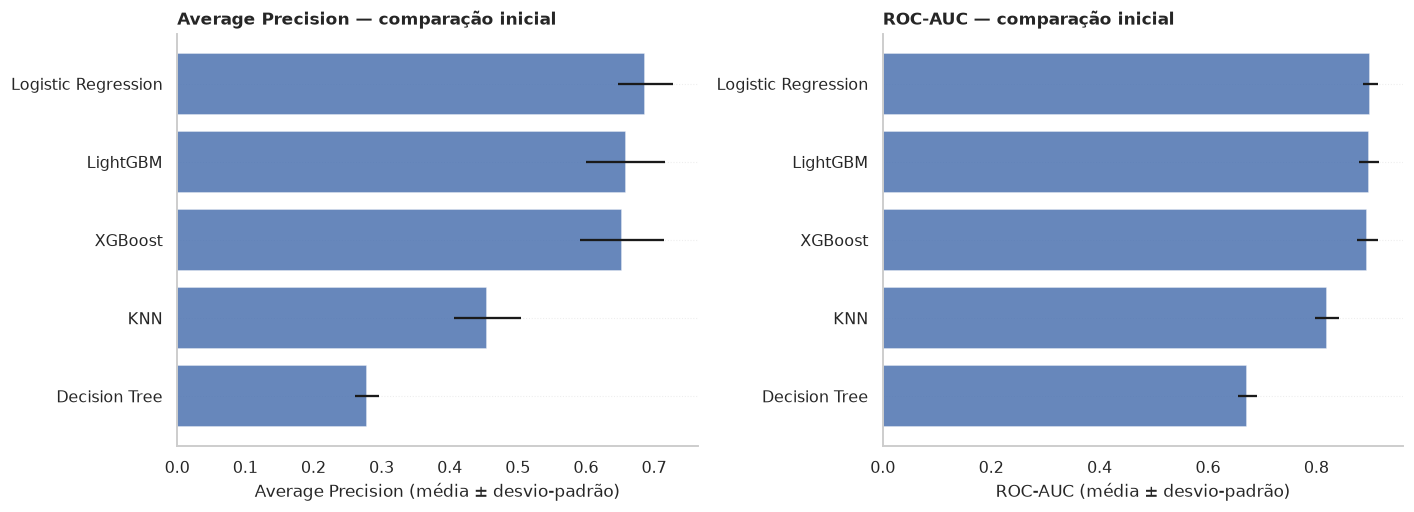

In [15]:
# Comparação visual das métricas dos algoritmos avaliados
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ap_plot = df_initial_comparison.sort_values("AP_mean", ascending=True)
axes[0].barh(ap_plot["Model"], ap_plot["AP_mean"], xerr=ap_plot["AP_std"], alpha=0.85)
axes[0].set_title("Average Precision — comparação inicial", loc="left")
axes[0].set_xlabel("Average Precision (média ± desvio-padrão)")
axes[0].grid(axis="x")

roc_plot = df_initial_comparison.sort_values("ROC_AUC_mean", ascending=True)
axes[1].barh(roc_plot["Model"], roc_plot["ROC_AUC_mean"], xerr=roc_plot["ROC_AUC_std"], alpha=0.85)
axes[1].set_title("ROC-AUC — comparação inicial", loc="left")
axes[1].set_xlabel("ROC-AUC (média ± desvio-padrão)")
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()

### 6.1 Critério de avanço

A comparação inicial serve para eliminar candidatos claramente inferiores, não para declarar o campeão. Três algoritmos seguem para a etapa de otimização:

- Regressão Logística;
- XGBoost;
- LightGBM.

KNN e Árvore de Decisão permanecem documentados como referências da comparação inicial, mas não recebem busca de hiperparâmetros nesta etapa.

## 7. Otimização e seleção do modelo

A otimização utiliza `RandomizedSearchCV`, com 20 combinações amostradas por algoritmo e cinco folds estratificados.

O critério principal de seleção dos hiperparâmetros é o **lucro observado médio por 1.000 clientes**, calculado em cada fold de validação. O lucro esperado também é registrado, enquanto Average Precision, ROC-AUC e Brier Score são mantidos como métricas complementares de desempenho preditivo.

- **Regressão Logística:** busca por `C` e quantidade de atributos mantidos pelo `SelectKBest`. O solver `liblinear` e a penalização L2 são mantidos fixos.
- **XGBoost:** busca por profundidade, número de estimadores, taxa de aprendizado, amostragem e regularização.
- **LightGBM:** busca por número de folhas, profundidade, número de estimadores, taxa de aprendizado, amostragem e regularização.

A seleção dos hiperparâmetros ocorre exclusivamente nas partições de treinamento e validação dos folds. O conjunto de teste não participa dessa etapa.

Os algoritmos de boosting usam uma thread por ajuste; o paralelismo fica a cargo do scikit-learn, evitando paralelismo aninhado excessivo.

In [16]:
# Cálculo da dimensionalidade transformada e definição dos valores válidos de k.
preprocessor_reference = build_preprocessor(
    numeric_features,
    categorical_features,
    scale_numeric=True,
).fit(X_train)
N_PREPROCESSED_FEATURES = len(preprocessor_reference.get_feature_names_out())

K_CANDIDATES = [k for k in [10, 15, 20] if k <= N_PREPROCESSED_FEATURES] + ["all"]

parameter_distributions = {
    "Logistic Regression": {
        "feature_selection__k": K_CANDIDATES,
        "model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    },
    "XGBoost": {
        "model__n_estimators": [150, 250, 350, 500],
        "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "model__min_child_weight": [2, 3, 5, 8, 10],
        "model__subsample": [0.70, 0.80, 0.90, 1.00],
        "model__colsample_bytree": [0.70, 0.80, 0.90, 1.00],
        "model__reg_lambda": [1.0, 3.0, 5.0, 10.0],
        "model__reg_alpha": [0.0, 0.1, 0.5, 1.0],
    },
    "LightGBM": {
        "model__n_estimators": [150, 250, 350, 500],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "model__max_depth": [-1, 3, 4, 5],
        "model__num_leaves": [5, 7, 10, 15],
        "model__min_child_samples": [15, 25, 40, 60],
        "model__subsample": [0.70, 0.80, 0.90, 1.00],
        "model__colsample_bytree": [0.70, 0.80, 0.90, 1.00],
        "model__reg_lambda": [1.0, 3.0, 5.0, 10.0],
        "model__reg_alpha": [0.0, 0.1, 0.5, 1.0],
    },
}

optimization_models = {
    "Logistic Regression": {
        "estimator": initial_models["Logistic Regression"]["estimator"],
        "scale_numeric": True,
        "use_feature_selection": True,
    },
    "XGBoost": {
        "estimator": initial_models["XGBoost"]["estimator"],
        "scale_numeric": False,
        "use_feature_selection": False,
    },
    "LightGBM": {
        "estimator": initial_models["LightGBM"]["estimator"],
        "scale_numeric": False,
        "use_feature_selection": False,
    },
}

print(f"Colunas após pré-processamento: {N_PREPROCESSED_FEATURES}")
print(f"Candidatos do SelectKBest: {K_CANDIDATES}")
print(f"Combinações amostradas por modelo: {N_ITER_SEARCH}")
print(f"Folds por combinação: {N_SPLITS}")
print(f"Ajustes previstos nesta etapa: {len(optimization_models) * N_ITER_SEARCH * N_SPLITS}")

Colunas após pré-processamento: 36
Candidatos do SelectKBest: [10, 15, 20, 'all']
Combinações amostradas por modelo: 20
Folds por combinação: 5
Ajustes previstos nesta etapa: 300


In [17]:
# Execução da otimização dos três candidatos e consolidação dos resultados
searches = {}
search_summary_rows = []

search_scoring = {
    "observed_profit_per_1000": observed_profit_per_1000_scorer,
    "expected_profit_per_1000": expected_profit_per_1000_scorer,
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "neg_brier_score": "neg_brier_score",
}

for model_name, config in optimization_models.items():
    print(f"\nIniciando otimização: {model_name}")

    pipeline = build_model_pipeline(
        config["estimator"],
        scale_numeric=config["scale_numeric"],
        use_feature_selection=config["use_feature_selection"],
        k="all",
    )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_distributions[model_name],
        n_iter=N_ITER_SEARCH,
        scoring=search_scoring,
        refit="observed_profit_per_1000",
        cv=cv_search,
        random_state=RANDOM_STATE + 2,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    search.fit(X_train, y_train)
    searches[model_name] = search

    results = pd.DataFrame(search.cv_results_)
    best_idx = search.best_index_

    best_result = results.loc[best_idx]

    search_summary_rows.append({
        "Model": model_name,

        "Best_ObservedProfit_per_1000_mean":
            best_result["mean_test_observed_profit_per_1000"],

        "Best_ObservedProfit_per_1000_std":
            best_result["std_test_observed_profit_per_1000"],

        "Best_ExpectedProfit_per_1000_mean":
            best_result["mean_test_expected_profit_per_1000"],

        "Best_AP_mean":
            best_result["mean_test_average_precision"],

        "Best_AP_std":
            best_result["std_test_average_precision"],

        "Best_ROC_AUC_mean":
            best_result["mean_test_roc_auc"],

        "Best_ROC_AUC_std":
            best_result["std_test_roc_auc"],

        "Best_Brier_mean":
            -best_result["mean_test_neg_brier_score"],

        "Best_params": search.best_params_,
    })

    print(f"Melhores parâmetros — {model_name}:")
    print(search.best_params_)

    print(
        "Lucro observado médio na validação cruzada: "
        f"{search.best_score_:.2f} MU / 1.000 clientes"
    )


Iniciando otimização: Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Melhores parâmetros — Logistic Regression:
{'model__C': 3.0, 'feature_selection__k': 20}
Lucro observado médio na validação cruzada: 587.77 MU / 1.000 clientes

Iniciando otimização: XGBoost
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Melhores parâmetros — XGBoost:
{'model__subsample': 1.0, 'model__reg_lambda': 3.0, 'model__reg_alpha': 0.0, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 2, 'model__learning_rate': 0.08, 'model__colsample_bytree': 0.7}
Lucro observado médio na validação cruzada: 587.66 MU / 1.000 clientes

Iniciando otimização: LightGBM
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Melhores parâmetros — LightGBM:
{'model__subsample': 1.0, 'model__reg_lambda': 1.0, 'model__reg_alpha': 0.5, 'model__num_leaves': 15, 'model__n_estimators': 150, 'model__min_child_samples': 40, 'model__max_depth': -1, 'model__

In [18]:
# Consolidação dos melhores resultados encontrados na otimização
df_search_summary = (
    pd.DataFrame(search_summary_rows)
    .sort_values(
        [
            "Best_ObservedProfit_per_1000_mean",
            "Best_ExpectedProfit_per_1000_mean",
            "Best_AP_mean",
        ],
        ascending=[False, False, False],
    )
    .reset_index(drop=True)
)

display(
    df_search_summary.style.format({
        "Best_ObservedProfit_per_1000_mean": "{:,.2f}",
        "Best_ObservedProfit_per_1000_std": "{:,.2f}",
        "Best_ExpectedProfit_per_1000_mean": "{:,.2f}",
        "Best_AP_mean": "{:.4f}",
        "Best_AP_std": "{:.4f}",
        "Best_ROC_AUC_mean": "{:.4f}",
        "Best_ROC_AUC_std": "{:.4f}",
        "Best_Brier_mean": "{:.4f}",
    })
)

,Model,Best_ObservedProfit_per_1000_mean,Best_ObservedProfit_per_1000_std,Best_ExpectedProfit_per_1000_mean,Best_AP_mean,Best_AP_std,Best_ROC_AUC_mean,Best_ROC_AUC_std,Best_Brier_mean,Best_params
0,LightGBM,588.85,50.59,451.12,0.6586,0.0281,0.8997,0.0155,0.0811,"{'model__subsample': 1.0, 'model__reg_lambda': 1.0, 'model__reg_alpha': 0.5, 'model__num_leaves': 15, 'model__n_estimators': 150, 'model__min_child_samples': 40, 'model__max_depth': -1, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}"
1,Logistic Regression,587.77,72.48,595.23,0.6786,0.0383,0.8956,0.0278,0.0792,"{'model__C': 3.0, 'feature_selection__k': 20}"
2,XGBoost,587.66,88.31,608.17,0.6709,0.0304,0.8991,0.0175,0.0791,"{'model__subsample': 1.0, 'model__reg_lambda': 3.0, 'model__reg_alpha': 0.0, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 2, 'model__learning_rate': 0.08, 'model__colsample_bytree': 0.7}"


### 7.1 Resultados da otimização

O resumo apresenta a melhor combinação de hiperparâmetros encontrada para cada algoritmo, considerando o lucro observado médio por 1.000 clientes nas validações cruzadas.

A tabela também registra lucro esperado, Average Precision, ROC-AUC e Brier Score, permitindo comparar o critério principal com indicadores complementares de desempenho preditivo e probabilístico.

O LightGBM apresentou o maior lucro observado médio, de **588,85 MU por 1.000 clientes**, com desvio-padrão de 50,59 MU. A Regressão Logística alcançou 587,77 MU (desvio-padrão de 72,48) e o XGBoost, 587,66 MU (desvio-padrão de 88,31). A diferença do LightGBM para os demais candidatos é pequena quando comparada à dispersão observada entre os folds.

As métricas complementares não indicam liderança uniforme do LightGBM: a Regressão Logística e o XGBoost apresentaram maiores valores médios de lucro esperado e Average Precision. Portanto, a seleção do LightGBM decorre especificamente de sua liderança no critério primário, o lucro observado por 1.000 clientes, e não de superioridade geral em todas as métricas.

A comparação entre os três candidatos utiliza os mesmos folds de busca, o mesmo limiar econômico e as mesmas premissas de negócio. O conjunto de teste permanece reservado e não participa da escolha do campeão.

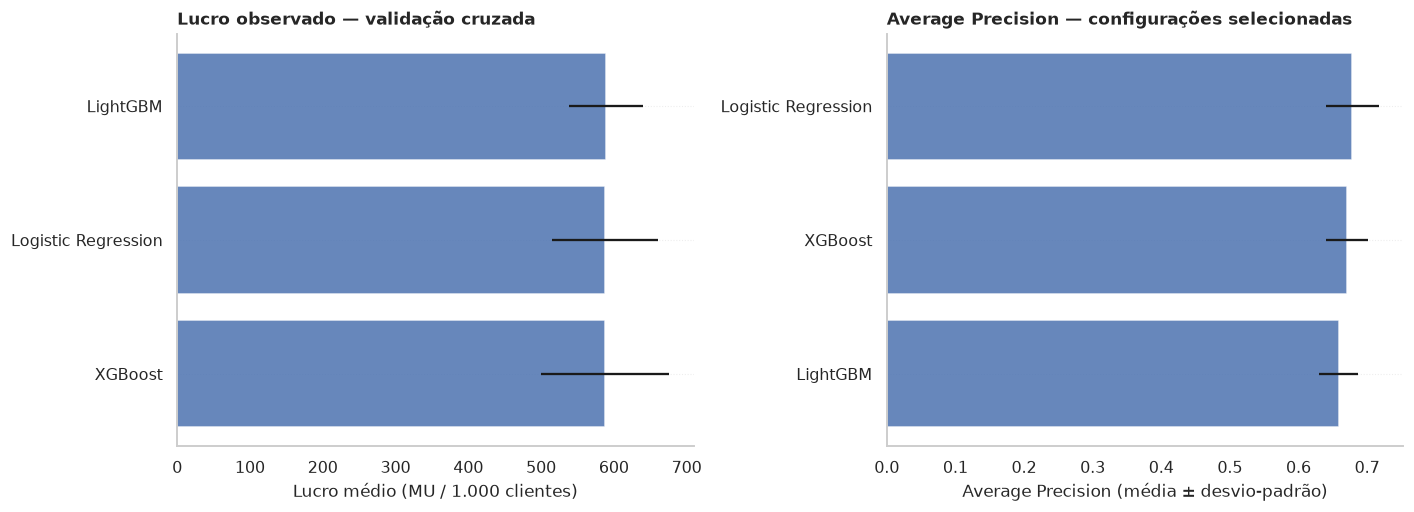

Candidato campeão: LightGBM
Lucro observado médio na validação cruzada: 588.85 MU / 1.000 clientes
Lucro esperado médio na validação cruzada: 451.12 MU / 1.000 clientes
Average Precision: 0.6586


In [19]:
# Comparação visual do lucro observado e da Average Precision após a otimização
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Lucro observado médio por 1.000 clientes
profit_plot = df_search_summary.sort_values(
    "Best_ObservedProfit_per_1000_mean",
    ascending=True,
)

axes[0].barh(
    profit_plot["Model"],
    profit_plot["Best_ObservedProfit_per_1000_mean"],
    xerr=profit_plot["Best_ObservedProfit_per_1000_std"],
    alpha=0.85,
)
axes[0].set_title("Lucro observado — validação cruzada", loc="left")
axes[0].set_xlabel("Lucro médio (MU / 1.000 clientes)")
axes[0].grid(axis="x")

# Average Precision das melhores configurações selecionadas pelo critério financeiro
ap_plot = df_search_summary.sort_values(
    "Best_AP_mean",
    ascending=True,
)

axes[1].barh(
    ap_plot["Model"],
    ap_plot["Best_AP_mean"],
    xerr=ap_plot["Best_AP_std"],
    alpha=0.85,
)
axes[1].set_title("Average Precision — configurações selecionadas", loc="left")
axes[1].set_xlabel("Average Precision (média ± desvio-padrão)")
axes[1].grid(axis="x")

plt.tight_layout()
plt.show()


# Pipelines otimizados e ajustados em todo o conjunto de treinamento
best_pipelines = {
    model_name: search.best_estimator_
    for model_name, search in searches.items()
}


# Seleção do campeão exclusivamente pelos resultados da validação cruzada
champion_model_name = df_search_summary.loc[0, "Model"]

champion_pipeline = best_pipelines[champion_model_name]

champion_training_cv = (
    df_search_summary.loc[
        df_search_summary["Model"] == champion_model_name
    ]
    .iloc[0]
    .to_dict()
)

print(f"Candidato campeão: {champion_model_name}")

print(
    "Lucro observado médio na validação cruzada: "
    f"{champion_training_cv['Best_ObservedProfit_per_1000_mean']:.2f} "
    "MU / 1.000 clientes"
)

print(
    "Lucro esperado médio na validação cruzada: "
    f"{champion_training_cv['Best_ExpectedProfit_per_1000_mean']:.2f} "
    "MU / 1.000 clientes"
)

print(
    f"Average Precision: {champion_training_cv['Best_AP_mean']:.4f}"
)


## 8. Avaliação final do modelo campeão

Após a seleção do candidato exclusivamente com os dados de treinamento, o pipeline campeão é avaliado no conjunto de teste, que não participou da comparação inicial, da otimização ou da escolha do modelo.

A avaliação inclui Average Precision, ROC-AUC, Brier Score, medidas auxiliares com limiar de 0,50 e métricas de priorização nos primeiros 10% e 20% dos scores.

O resultado desta etapa representa a avaliação final do candidato selecionado. Não será utilizado para substituir o campeão ou ajustar novamente os hiperparâmetros.


In [20]:
# Estimativa das probabilidades do campeão no conjunto de teste
champion_probability = champion_pipeline.predict_proba(X_test)[:, 1]

# Classificação de referência com limiar de 0,50
champion_prediction_050 = (
    champion_probability >= 0.50
).astype("int8")

# Métricas de priorização
p10, r10, _ = precision_recall_at_k(
    y_test,
    champion_probability,
    0.10,
)

p20, r20, _ = precision_recall_at_k(
    y_test,
    champion_probability,
    0.20,
)


champion_test_metrics = {
    "Model": champion_model_name,

    "AveragePrecision": average_precision_score(
        y_test,
        champion_probability,
    ),

    "ROC_AUC": roc_auc_score(
        y_test,
        champion_probability,
    ),

    "BrierScore": brier_score_loss(
        y_test,
        champion_probability,
    ),

    "BalancedAccuracy@0.50": balanced_accuracy_score(
        y_test,
        champion_prediction_050,
    ),

    "Precision@0.50": precision_score(
        y_test,
        champion_prediction_050,
        zero_division=0,
    ),

    "Recall@0.50": recall_score(
        y_test,
        champion_prediction_050,
        zero_division=0,
    ),

    "F1@0.50": f1_score(
        y_test,
        champion_prediction_050,
        zero_division=0,
    ),

    "Precision@10%": p10,
    "Recall@10%": r10,
    "Precision@20%": p20,
    "Recall@20%": r20,
}


df_champion_test_metrics = pd.DataFrame([
    champion_test_metrics
])

display(
    df_champion_test_metrics.style.format({
        col: "{:.4f}"
        for col in df_champion_test_metrics.select_dtypes(
            include="number"
        ).columns
    })
)

,Model,AveragePrecision,ROC_AUC,BrierScore,BalancedAccuracy@0.50,Precision@0.50,Recall@0.50,F1@0.50,Precision@10%,Recall@10%,Precision@20%,Recall@20%
0,LightGBM,0.6994,0.9178,0.0765,0.7010,0.8235,0.4179,0.5545,0.7333,0.4925,0.5556,0.7463


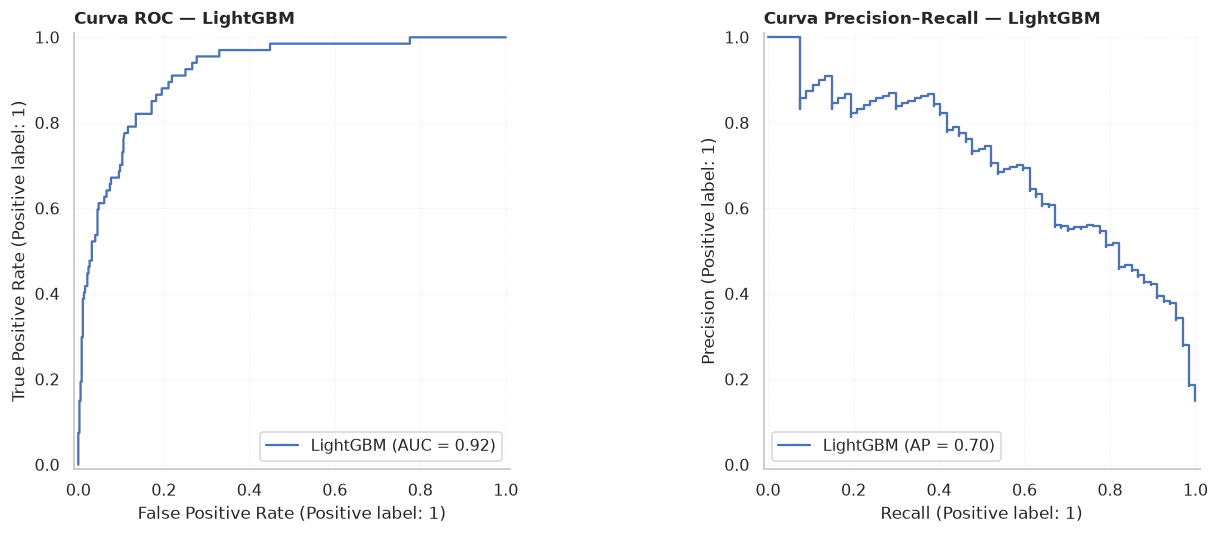

In [21]:
# Visualização das curvas ROC e Precision-Recall do modelo campeão
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test,
    champion_probability,
    ax=axes[0],
    name=champion_model_name,
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    champion_probability,
    ax=axes[1],
    name=champion_model_name,
)

axes[0].set_title(
    f"Curva ROC — {champion_model_name}",
    loc="left",
)

axes[1].set_title(
    f"Curva Precision–Recall — {champion_model_name}",
    loc="left",
)

plt.tight_layout()
plt.show()

## 9. Avaliação econômica do modelo campeão

O candidato campeão já foi selecionado com base na rentabilidade média observada nas validações cruzadas do conjunto de treinamento.

Nesta etapa, aplicamos a política econômica ao conjunto de teste para observar o resultado financeiro do modelo diante de registros que não participaram do treinamento ou da seleção.

O case utiliza as seguintes premissas simplificadas:

- custo por contato: **3 MU**;
- receita por conversão: **11 MU**;
- contribuição esperada por cliente contatado: `11 × probabilidade − 3`.

O ponto de equilíbrio ocorre quando `11p − 3 = 0`, portanto o limiar econômico é `3 / 11 = 27,27%`. A política desta simulação contata os clientes cuja probabilidade estimada é igual ou superior ao limiar.

Serão apresentados:

- **Lucro esperado:** soma das probabilidades estimadas dos selecionados, multiplicada pela receita, menos o custo dos contatos.
- **Lucro observado:** conversões efetivamente encontradas entre os selecionados, multiplicadas pela receita, menos o custo dos contatos.

O resultado não será utilizado para alterar a escolha do campeão.

In [22]:
# Aplicação da simulação econômica do campeão no conjunto de teste
champion_test_economics = simulate_campaign_economics(
    y_true=y_test,
    probabilities=champion_probability,
    threshold=ECONOMIC_THRESHOLD,
    contact_cost=CONTACT_COST,
    revenue_per_conversion=REVENUE_PER_CONVERSION,
)

champion_test_economics["Model"] = champion_model_name

df_champion_test_economics = pd.DataFrame([
    champion_test_economics
])

display(
    df_champion_test_economics.style.format({
        "SelectionRate": "{:.2%}",
        "ExpectedConversions": "{:,.2f}",
        "ExpectedResponseRateSelected": "{:.2%}",
        "ExpectedRevenue_MU": "{:,.2f}",
        "ContactCost_MU": "{:,.2f}",
        "ExpectedProfit_MU": "{:,.2f}",
        "ObservedResponseRateSelected": "{:.2%}",
        "ObservedRevenue_MU": "{:,.2f}",
        "ObservedProfit_MU": "{:,.2f}",
    })
)


# Referência: contato indiscriminado de todos os clientes do conjunto de teste
all_test_customers = len(y_test)
all_test_conversions = int(y_test.sum())

all_test_cost = all_test_customers * CONTACT_COST
all_test_revenue = all_test_conversions * REVENUE_PER_CONVERSION
all_test_profit = all_test_revenue - all_test_cost

print("\nBenchmark — contato indiscriminado no conjunto de teste")

print(f"Clientes contatados: {all_test_customers:,}")
print(
    f"Conversões observadas: {all_test_conversions:,} "
    f"({y_test.mean():.2%})"
)
print(f"Custo: {all_test_cost:,.2f} {ECONOMIC_UNIT}")
print(f"Receita observada: {all_test_revenue:,.2f} {ECONOMIC_UNIT}")
print(f"Lucro observado: {all_test_profit:,.2f} {ECONOMIC_UNIT}")

,CustomersTotal,CustomersSelected,SelectionRate,ExpectedConversions,ExpectedResponseRateSelected,ExpectedRevenue_MU,ContactCost_MU,ExpectedProfit_MU,ObservedConversions,ObservedResponseRateSelected,ObservedRevenue_MU,ObservedProfit_MU,Model
0,446,72,16.14%,35.93,49.90%,395.24,216.00,179.24,44,61.11%,484.00,268.00,LightGBM



Benchmark — contato indiscriminado no conjunto de teste
Clientes contatados: 446
Conversões observadas: 67 (15.02%)
Custo: 1,338.00 MU
Receita observada: 737.00 MU
Lucro observado: -601.00 MU


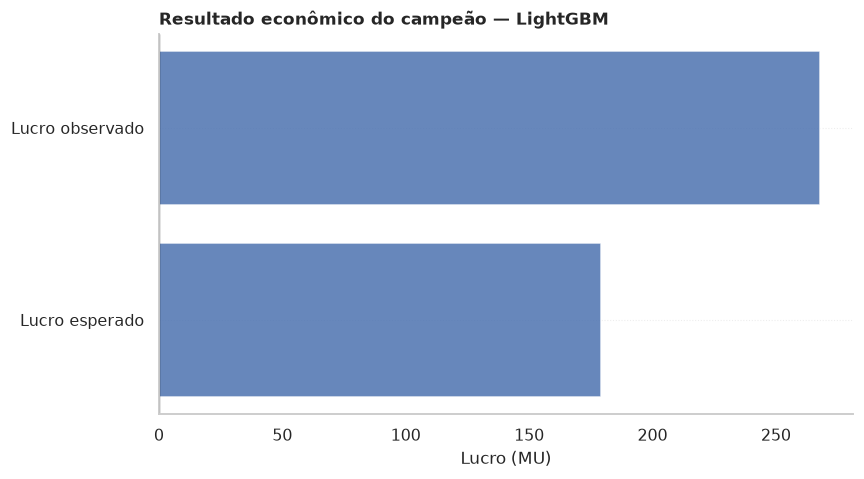

In [23]:
# Preparação dos resultados para a visualização econômica
profit_values = [
    champion_test_economics["ExpectedProfit_MU"],
    champion_test_economics["ObservedProfit_MU"],
]

profit_labels = [
    "Lucro esperado",
    "Lucro observado",
]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.barh(
    profit_labels,
    profit_values,
    alpha=0.85,
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    f"Resultado econômico do campeão — {champion_model_name}",
    loc="left",
)

ax.set_xlabel(f"Lucro ({ECONOMIC_UNIT})")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

### 9.1 Interpretação dos resultados

O LightGBM foi selecionado exclusivamente pelo maior lucro observado médio por 1.000 clientes nas validações cruzadas do conjunto de treinamento. Sua vantagem sobre a Regressão Logística e o XGBoost foi marginal, mas corresponde ao critério econômico principal definido para o CampaignScore.

Na avaliação do conjunto de teste, o limiar econômico de 27,27% selecionou **72 dos 446 clientes (16,14%)**. Entre os selecionados, **44 responderam**, resultando em taxa observada de resposta de **61,11%**, ante prevalência de 15,02% no conjunto completo. Os 44 clientes correspondem a **65,67% das 67 respostas positivas** existentes no teste.

A política apresentou lucro esperado de **179,24 MU** e lucro observado de **268,00 MU**. Como referência, o contato indiscriminado dos 446 clientes teria produzido prejuízo observado de **601,00 MU** sob as premissas econômicas do case.

Esses resultados demonstram capacidade de priorização na amostra de teste: a política concentrou uma parcela relevante das respostas positivas em uma fração menor da base. O teste avalia somente o LightGBM selecionado; portanto, não permite afirmar que ele selecionaria mais clientes ou teria maior lucro de teste que os demais candidatos.

O conjunto de teste contém um número limitado de clientes e conversões. O resultado financeiro é sensível à composição da amostra e deve ser interpretado como avaliação da rodada, não como garantia de rentabilidade futura ou estimativa causal de incrementalidade.

## 10. Interpretação do modelo campeão

As análises seguintes são aplicadas somente ao candidato selecionado. A matriz de confusão utiliza o limiar econômico (27,27%), e não o limiar genérico de 0,50.

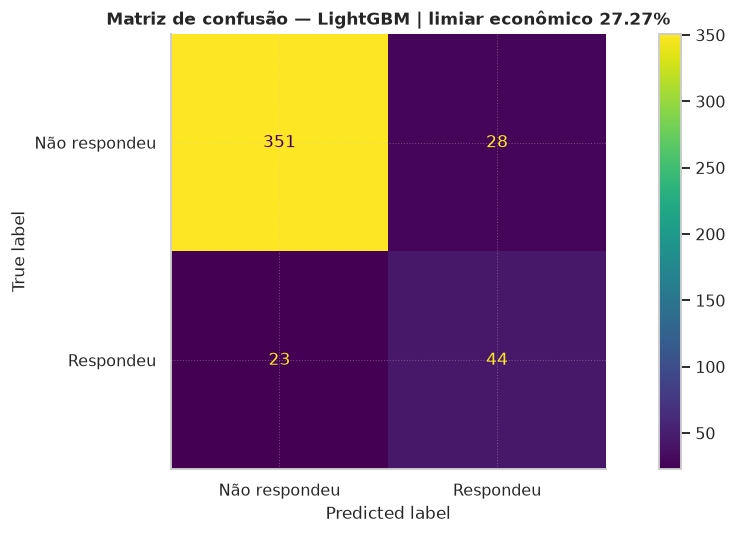

Relatório de classificação no limiar econômico:
Predito    0   1
Real            
0        351  28
1         23  44


In [24]:
# Classificação dos clientes utilizando o limiar econômico
champion_prediction_economic = (champion_probability >= ECONOMIC_THRESHOLD).astype("int8")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    champion_prediction_economic,
    display_labels=["Não respondeu", "Respondeu"],
    values_format="d",
)
plt.title(f"Matriz de confusão — {champion_model_name} | limiar econômico {ECONOMIC_THRESHOLD:.2%}")
plt.tight_layout()
plt.show()

print("Relatório de classificação no limiar econômico:")
print(pd.crosstab(
    pd.Series(y_test.to_numpy(), name="Real"),
    pd.Series(champion_prediction_economic, name="Predito"),
    rownames=["Real"],
    colnames=["Predito"],
))


### 10.1 Importância por permutação

A importância por permutação mede quanto a Average Precision diminui quando cada feature original é embaralhada, mantendo o restante do pipeline fixo. O cálculo é realizado na escala das 21 colunas de entrada, antes do One-Hot Encoding.

A análise é interpretativa: uma importância elevada indica dependência preditiva do modelo nesta amostra, não causalidade.

Os resultados são utilizados para compreender o comportamento do campeão e não serão utilizados para selecionar novas features ou alterar o modelo nesta rodada experimental.


In [25]:
# Cálculo da importância por permutação no conjunto de teste
champion_permutation = permutation_importance(
    champion_pipeline,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

df_champion_importance = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "ImportanceMean": champion_permutation.importances_mean,
        "ImportanceStd": champion_permutation.importances_std,
    })
    .sort_values("ImportanceMean", ascending=False)
    .reset_index(drop=True)
)

display(df_champion_importance)

,Feature,ImportanceMean,ImportanceStd
0,Recency,0.1648,0.0370
1,FamilyProfile,0.0897,0.0149
2,AcceptedCmp5,0.0897,0.0222
3,TenureDays,0.0812,0.0258
4,MntMeatProducts,0.0803,0.0252
5,AcceptedCmp3,0.0512,0.0131
6,AcceptedCmp1,0.0458,0.0136
7,Income,0.0214,0.0109
8,NumActiveChannels,0.0202,0.0136
9,PreferredChannel,0.0178,0.0125


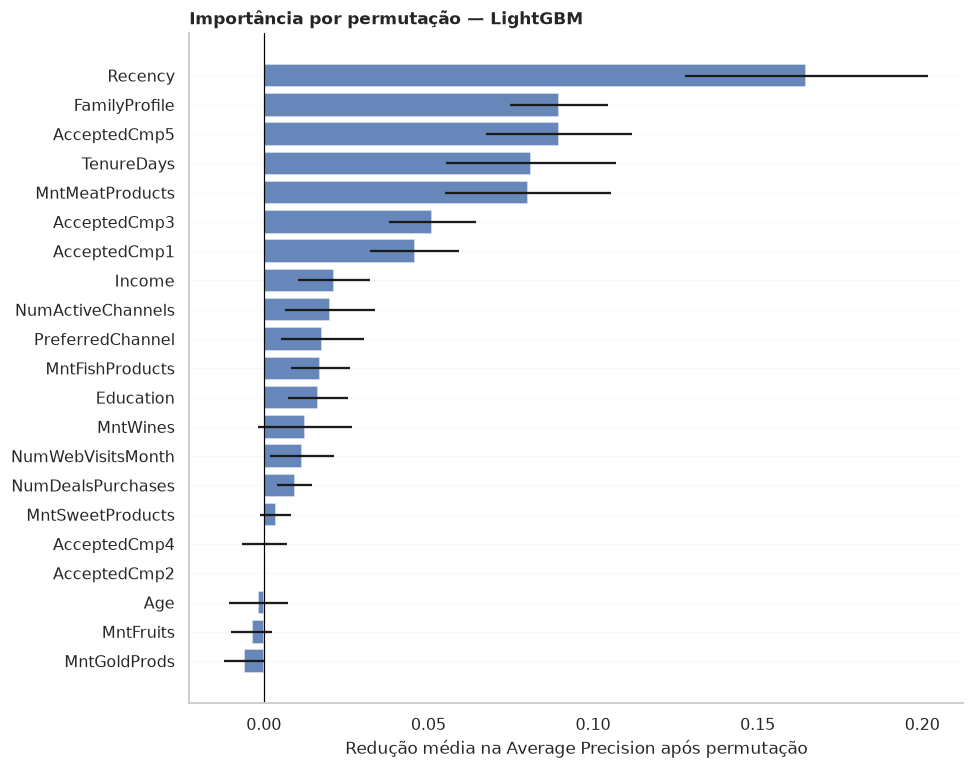

In [26]:
# Preparação da importância por permutação para visualização
importance_plot = df_champion_importance.sort_values("ImportanceMean", ascending=True)
fig, ax = plt.subplots(figsize=(9, max(4, len(importance_plot) * 0.34)))
ax.barh(
    importance_plot["Feature"],
    importance_plot["ImportanceMean"],
    xerr=importance_plot["ImportanceStd"],
    alpha=0.85,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Importância por permutação — {champion_model_name}", loc="left")
ax.set_xlabel("Redução média na Average Precision após permutação")
ax.set_ylabel("")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

### 10.2 Distribuição dos scores

A distribuição compara os scores atribuídos aos clientes que responderam e aos que não responderam. A sobreposição entre as distribuições é esperada; o objetivo é verificar se o modelo tende a atribuir scores mais altos aos positivos.

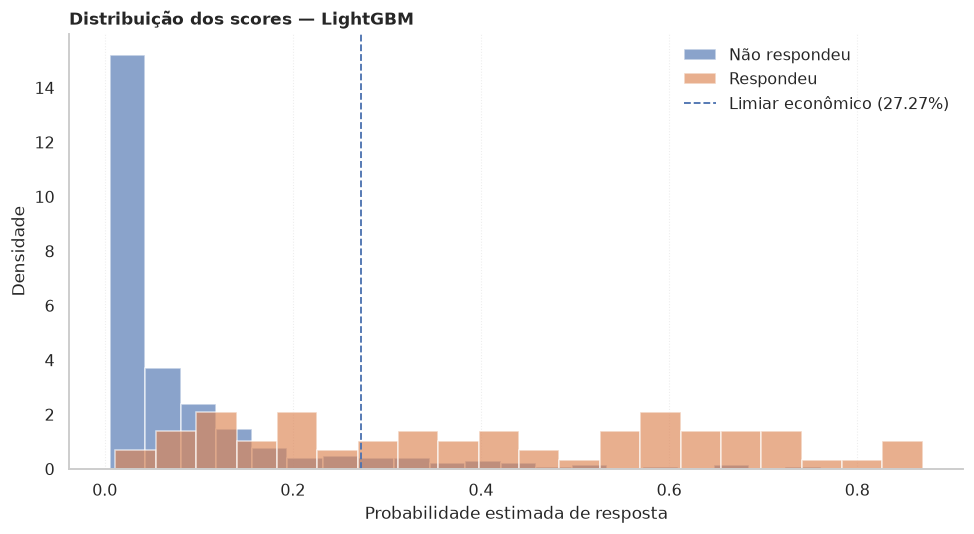

In [27]:
# Visualização da distribuição dos scores por classe real
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(
    champion_probability[np.asarray(y_test) == 0],
    bins=20,
    alpha=0.65,
    density=True,
    label="Não respondeu",
)
ax.hist(
    champion_probability[np.asarray(y_test) == 1],
    bins=20,
    alpha=0.65,
    density=True,
    label="Respondeu",
)
ax.axvline(ECONOMIC_THRESHOLD, linestyle="--", linewidth=1.2, label=f"Limiar econômico ({ECONOMIC_THRESHOLD:.2%})")
ax.set_title(f"Distribuição dos scores — {champion_model_name}", loc="left")
ax.set_xlabel("Probabilidade estimada de resposta")
ax.set_ylabel("Densidade")
ax.legend(frameon=False)
ax.grid(axis="y")
plt.tight_layout()
plt.show()

### 10.3 Calibração das probabilidades

A curva de calibração compara a probabilidade média prevista em cada faixa com a frequência positiva observada. Um modelo bem calibrado tende a permanecer próximo da diagonal.

O Brier Score complementa a leitura: quanto menor, melhor a combinação entre acurácia probabilística e calibração. A curva é especialmente importante porque o limiar econômico é aplicado diretamente às probabilidades estimadas.

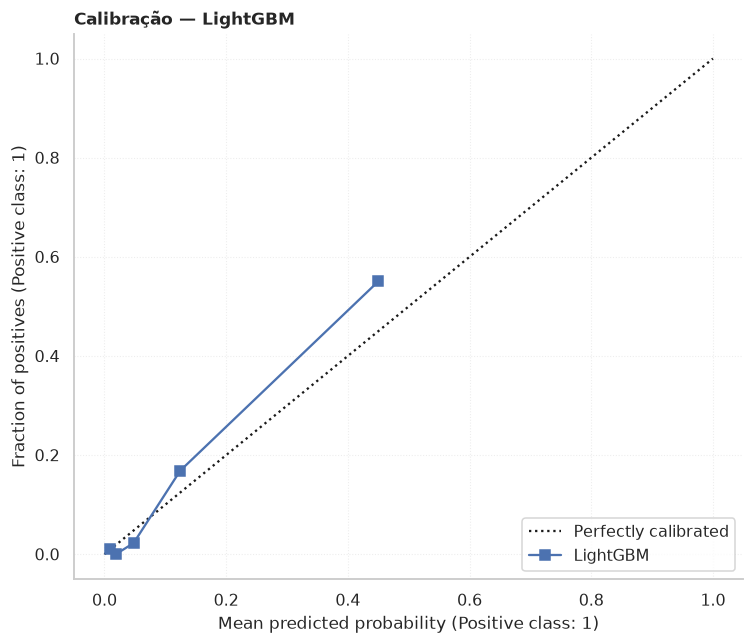

Brier Score do candidato campeão: 0.0765


In [28]:
# Avaliação visual da calibração das probabilidades estimadas
fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_test,
    champion_probability,
    n_bins=5,
    strategy="quantile",
    name=champion_model_name,
    ax=ax,
)
ax.set_title(f"Calibração — {champion_model_name}", loc="left")
ax.grid(True, linestyle=":", alpha=0.35)
plt.tight_layout()
plt.show()

champion_brier = brier_score_loss(y_test, champion_probability)
print(f"Brier Score do candidato campeão: {champion_brier:.4f}")

## 11. Empacotamento e exportação do modelo

Após a avaliação final, o pipeline campeão é ajustado novamente utilizando toda a base curada disponível.

Isso maximiza os dados utilizados no artefato operacional. A avaliação no conjunto de teste permanece registrada como resultado da rodada anterior, realizada com o pipeline treinado exclusivamente no conjunto de treinamento.

O arquivo `.joblib` contém o pré-processamento e o estimador em um único objeto. Para inferência, basta fornecer as 21 features de entrada — `Response` não é necessária. `ID`, quando existir no arquivo de entrada, deve ser mantido fora do pipeline e associado às probabilidades pelo processo operacional posterior.

O diretório de saída é centralizado em `src.paths.PREDICTIVE_FOLDER`.

In [29]:
# Ajuste final do pipeline campeão com toda a base disponível.
PREDICTIVE_FOLDER.mkdir(parents=True, exist_ok=True)

final_pipeline = clone(champion_pipeline)
final_pipeline.fit(X, y)

# Exportação do modelo
model_name = champion_model_name.lower().replace(" ", "_")

model_path = (
    PREDICTIVE_FOLDER / f"{model_name}_classifier_v1.joblib"
)

joblib.dump(final_pipeline, model_path, compress=3)

['/home/jhonathan/SDL/campaignscore/models/predictive/lightgbm_classifier_v1.joblib']

In [30]:
# Organização dos metadados do modelo
predictive_config = {
    "model_name": champion_model_name,
    "artifact_version": "1.0.0",
    "features": X.columns.tolist(),
    "target": TARGET,
    "identifier_column": ID_COL,

    "best_hyperparameters": searches[
        champion_model_name
    ].best_params_,

    "selection": {
        "criterion": "observed_profit_per_1000",
        "validation_folds": N_SPLITS,
        "results": {
            key: value
            for key, value in champion_training_cv.items()
            if key not in ["Model", "Best_params"]
        },
    },

    "test_metrics": champion_test_metrics,
    "test_economics": champion_test_economics,

    "economic_assumptions": {
        "contact_cost": CONTACT_COST,
        "revenue_per_conversion": REVENUE_PER_CONVERSION,
        "threshold": ECONOMIC_THRESHOLD,
    },
}

metadata_path = model_path.with_suffix(".metadata.json")

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(
        predictive_config,
        file,
        ensure_ascii=False,
        indent=4,
        default=lambda value: (
            value.item() if isinstance(value, np.generic) else str(value)
        ),
    )

In [31]:
# Verificação da persistência e reprodutibilidade do pipeline exportado
loaded_pipeline = joblib.load(model_path)

np.testing.assert_allclose(
    final_pipeline.predict_proba(X.head(10)),
    loaded_pipeline.predict_proba(X.head(10)),
)

print("Exportação concluída e validada.")
print(f"Modelo: {model_path}")
print(f"Metadados: {metadata_path}")

Exportação concluída e validada.
Modelo: /home/jhonathan/SDL/campaignscore/models/predictive/lightgbm_classifier_v1.joblib
Metadados: /home/jhonathan/SDL/campaignscore/models/predictive/lightgbm_classifier_v1.metadata.json


## 12. Conclusão

A modelagem preditiva foi desenvolvida sobre uma base de **2.229 clientes e 21 features**, com divisão estratificada entre treinamento (1.783 registros) e teste (446 registros). Foram comparados cinco algoritmos e realizada a otimização de hiperparâmetros para Regressão Logística, XGBoost e LightGBM, utilizando o lucro observado médio por 1.000 clientes como critério principal de seleção.

O **LightGBM** foi selecionado por apresentar o maior lucro observado médio na validação cruzada, de **588,85 MU por 1.000 clientes**, com desvio-padrão de 50,59 MU. A vantagem sobre a Regressão Logística (587,77 MU) e o XGBoost (587,66 MU) foi marginal. As métricas complementares não indicaram superioridade uniforme: Regressão Logística e XGBoost obtiveram maiores valores médios de lucro esperado e Average Precision. A escolha do LightGBM reflete, portanto, o critério econômico observado previamente definido.

No conjunto de teste, o modelo alcançou **Average Precision de 0,6994**, **ROC-AUC de 0,9178** e **Brier Score de 0,0765**. Na priorização dos 10% com maiores scores, apresentou precisão de **73,33%** e recall de **49,25%**.

Na simulação econômica, com limiar de **27,27%**, foram selecionados **72 clientes (16,14% do teste)**. Entre eles, 44 responderam, correspondendo a uma taxa observada de resposta de **61,11%** e à captura de **65,67% das 67 respostas positivas** do conjunto de teste. A política apresentou lucro esperado de **179,24 MU** e lucro observado de **268,00 MU**. Sob as mesmas premissas, o contato indiscriminado dos 446 clientes resultaria em prejuízo observado de **601,00 MU**.

A análise por permutação destacou `Recency`, `FamilyProfile`, `AcceptedCmp5`, `TenureDays` e `MntMeatProducts` como as cinco features com maior redução média de Average Precision quando embaralhadas. Essa importância representa dependência preditiva observada na amostra, não contribuição causal.

Como resultado, o pipeline campeão foi ajustado novamente sobre toda a base disponível e empacotado em formato Joblib, acompanhado de metadados com as features, hiperparâmetros, critério de seleção, métricas e premissas econômicas.

Os resultados financeiros representam uma simulação baseada nas premissas simplificadas do case e na amostra de teste. Não constituem garantia de rentabilidade futura nem estimativa causal do impacto incremental das campanhas.